## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

## Names: Enya Tran, Simeng Zhang

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, A means pump and B means not.

The point estimate of the ATE is -0.01. The negative ATE indicates that patients in Group A (invasive strategy) had a 1 percentage point lower survival rate compared to those in Group B (conservative strategy). Based on this point estimate, I would rather not get the intra aortic balloon pump.

In [3]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  290   99
Invasive      293   95 

Estimated ATE:  -0.01


**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is very important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms).

In [4]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    
    ate_t = oat - obt # Compute ATE for this bootstrap sample

    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

The bootstrapped distributions for both groups overlap significantly, and are centered around survival rates of 24.5% for Invasive and 25.5% for Conservative. The Conservative group is slightly shifted to the right in the KDE plot and stays to the right in the ECDF plot, showing a marginally higher survival rate. But the difference is small relative to the variability in the bootstrap estimates.

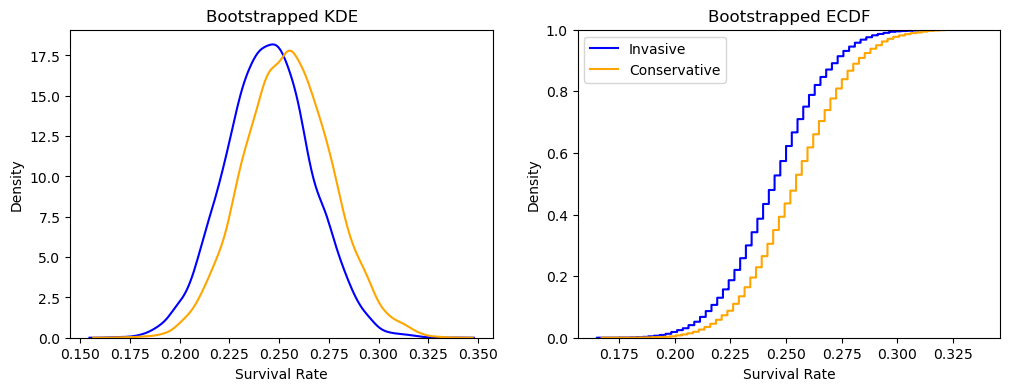

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

**4.** Make a plot of the KDE and ECDF for the ATE. 

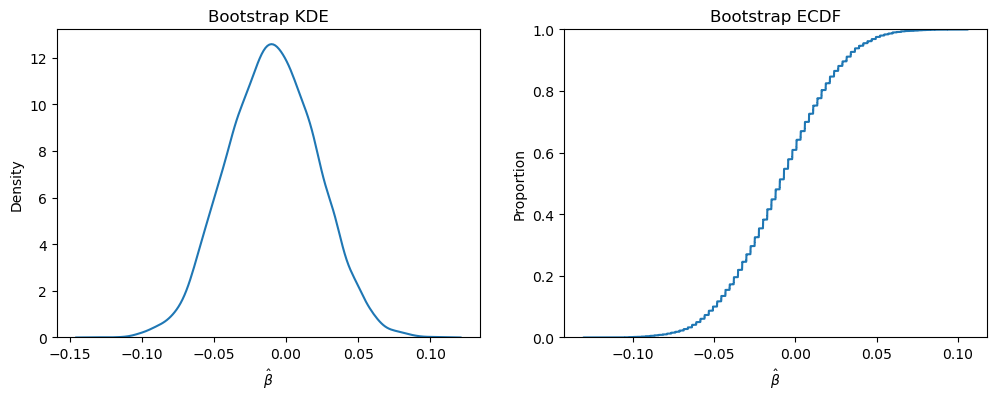

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

All calculated confidence intervals contain 0. Because 0 lies well within these intervals, we fail to reject the null hypothesis of no treatment effect at standard significance levels. There is insufficient evidence to conclude that the intra aortic balloon pump is effective compared to conservative treatment.

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.05863667  0.04180028]
95% CI: [-0.0688522   0.04959203]
99% CI: [-0.08944429  0.07010452]


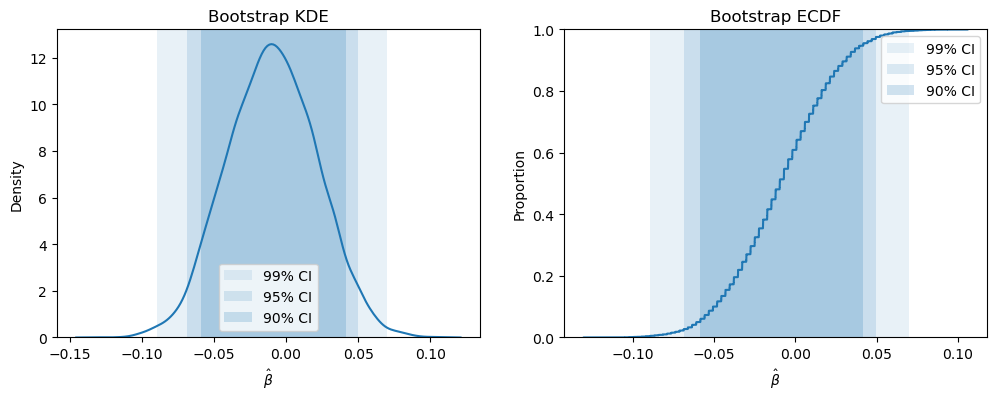

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

The estimated ATE is approximately −0.01, indicating that the Invasive group had a survival rate about 1 percentage point lower than the Conservative group in this sample. However, the 90%, 95%, and 99% bootstrap confidence intervals all include zero, so we fail to reject the null hypothesis that the ATE is zero. Therefore, there is insufficient evidence to conclude that the treatments differ in average survival outcomes or to determine which treatment is more effective. This also does not prove that the two treatments are equally effective.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

### 1.

In [3]:
df = pd.read_csv('./data/diabetes.csv')

## Crosstabs
print(pd.crosstab( df['treatment'], df['outcome']), '\n')

# Average outcomes (success = 1, failure = 0)
df['success'] = (df['outcome'] == 'success').astype(int)

print(df.groupby('treatment')['success'].mean().round(3))

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

treatment
lifestyle    0.534
met          0.483
rosi         0.614
Name: success, dtype: float64


### 2.

In [4]:
## Bootstrapping:
R = 10_000

df_a = df.loc[df['treatment'] == 'lifestyle', :]
df_b = df.loc[df['treatment'] == 'met', :]
df_c = df.loc[df['treatment'] == 'rosi', :]

outcome_a = []
outcome_b = []
outcome_c = []

for t in range(R):
    ## Resample within each group:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)
    df_ct = df_c.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['success'].mean()
    obt = df_bt['success'].mean()
    oct = df_ct['success'].mean()

    ## Store results:
    outcome_a.append(oat)
    outcome_b.append(obt)
    outcome_c.append(oct)


### 3.

Both KDEs and ECDFs show that Rosi has the highest average success rate (61.4%), followed by Lifestyle (53.4%) and Met (48.3%). Specifically, Rosi's distribution is shifted to the outermost right. Metformin and lifestyle show substantial overlap, while metformin and rosiglitazone are more clearly separated. Pairwise confidence intervals are needed to assess statistical significance.

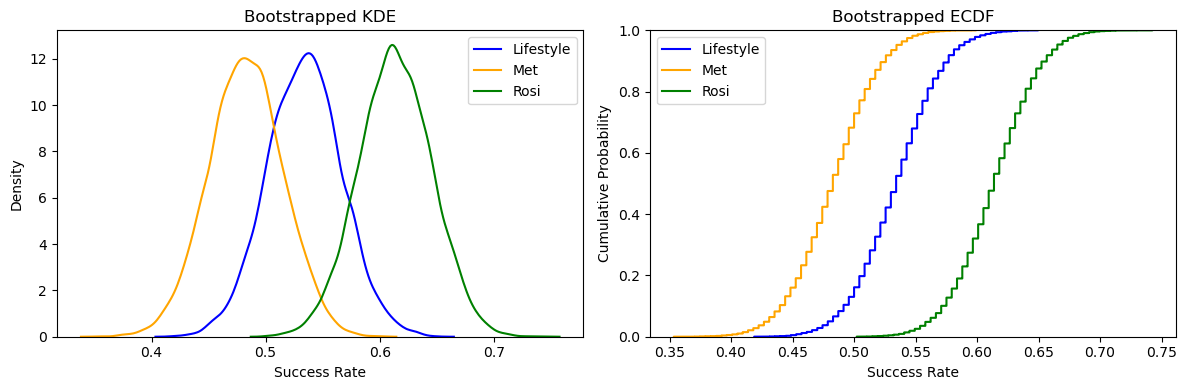

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# KDE plot
sns.kdeplot(outcome_a, label='Lifestyle', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Met', color='orange', ax=ax[0])
sns.kdeplot(outcome_c, label='Rosi', color='green', ax=ax[0])
ax[0].set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')
ax[0].legend()

# ECDF plot
sns.ecdfplot(outcome_a, label='Lifestyle', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Met', color='orange', ax=ax[1])
sns.ecdfplot(outcome_c, label='Rosi', color='green', ax=ax[1])
ax[1].set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Cumulative Probability')
ax[1].legend()

plt.tight_layout()
plt.show()

### 4. 

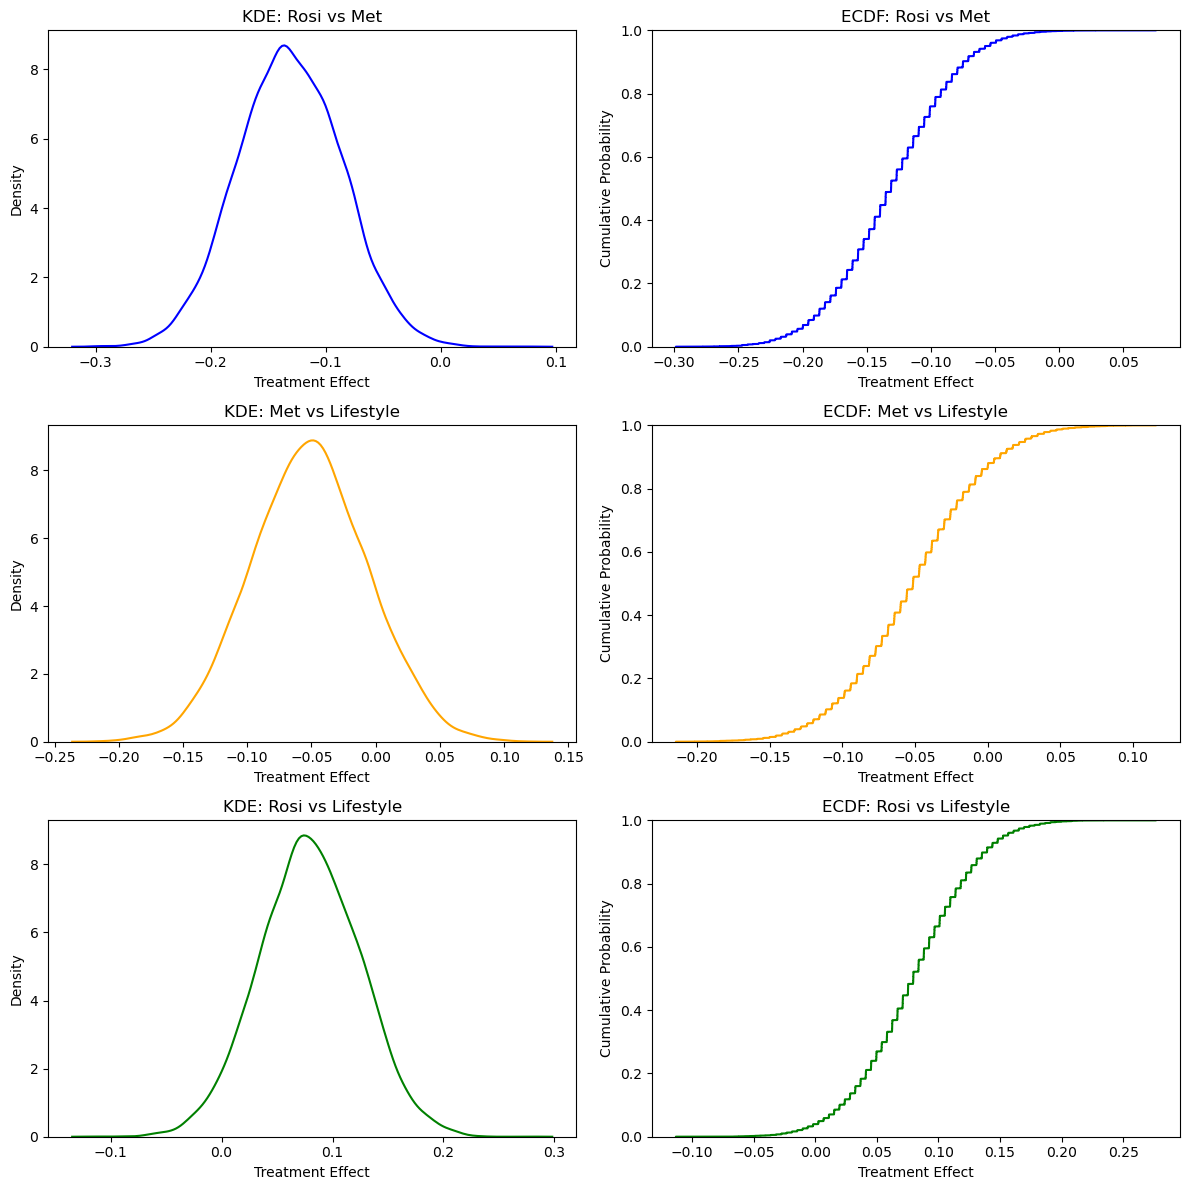

In [ ]:

## Compute treatment effects:
met_rosi = np.array(outcome_b) - np.array(outcome_c)
met_lifestyle = np.array(outcome_b) - np.array(outcome_a)
rosi_lifestyle = np.array(outcome_c) - np.array(outcome_a)

## Create 6 charts (3 rows x 2 columns):
fig, ax = plt.subplots(3, 2, figsize=(12, 12))

# Rosi vs Met
sns.kdeplot(met_rosi, color='blue', ax=ax[0, 0])
ax[0, 0].set(title='KDE: Met vs Rosi', xlabel='Treatment Effect', ylabel='Density')

sns.ecdfplot(met_rosi, color='blue', ax=ax[0, 1])
ax[0, 1].set(title='ECDF: Met vs Rosi', xlabel='Treatment Effect', ylabel='Cumulative Probability')

# Met vs Lifestyle
sns.kdeplot(met_lifestyle, color='orange', ax=ax[1, 0])
ax[1, 0].set(title='KDE: Met vs Lifestyle', xlabel='Treatment Effect', ylabel='Density')

sns.ecdfplot(met_lifestyle, color='orange', ax=ax[1, 1])
ax[1, 1].set(title='ECDF: Met vs Lifestyle', xlabel='Treatment Effect', ylabel='Cumulative Probability')

# Rosi vs Lifestyle
sns.kdeplot(rosi_lifestyle, color='green', ax=ax[2, 0])
ax[2, 0].set(title='KDE: Rosi vs Lifestyle', xlabel='Treatment Effect', ylabel='Density')

sns.ecdfplot(rosi_lifestyle, color='green', ax=ax[2, 1])
ax[2, 1].set(title='ECDF: Rosi vs Lifestyle', xlabel='Treatment Effect', ylabel='Cumulative Probability')

plt.tight_layout()
plt.show()


### 5.

The 95% bootstrap confidence interval for Met − Rosi excludes zero and is entirely negative, indicating that rosiglitazone has a significantly higher success rate than metformin. The intervals for Met − Lifestyle and Rosi − Lifestyle both include zero, so we fail to reject the null hypothesis of zero ATE for these comparisons. Rosiglitazone has the highest observed success rate, but there is insufficient evidence to establish that it is more effective than lifestyle adjustments.

In [ ]:
## Compute 95% confidence intervals:
ci_met_rosi = np.quantile(met_rosi, [0.025, 0.975])
ci_met_lifestyle = np.quantile(met_lifestyle, [0.025, 0.975])
ci_rosi_lifestyle = np.quantile(rosi_lifestyle, [0.025, 0.975])

print('Met vs Rosi:', np.round(ci_met_rosi, 3))
print('Met vs Lifestyle:', np.round(ci_met_lifestyle, 3))
print('Rosi vs Lifestyle:', np.round(ci_rosi_lifestyle, 3))

Met vs Rosi: [-0.221 -0.041]
Met vs Lifestyle: [-0.141  0.039]
Rosi vs Lifestyle: [-0.01   0.169]
